# Import Libraries

In [44]:
import re
import html
import string
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# **1. Load Dataset - Train / Test Split**

In [45]:
df = pd.read_csv('train.csv')
df

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1
...,...,...,...,...,...
7608,10869,NaN,NaN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NaN,NaN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided ...,1


## Περιγραφή Μεταβλητών

*   **id** : Αναγνωριστικό του tweet.
*   **keyword** : Λέξη-κλειδί του tweet (μπορεί να λείπει).
*   **location** : Τοποθεσία από την οποία στάλθηκε το tweet (μπορεί να λείπει).
*   **text** : Το κείμενο του tweet.
*   **target** : 1 = αφορά πραγματική φυσική καταστροφή, 0 = δεν αφορά.

## Διαχωρισμός Train - Test Dataset

Ποσοστά 90-10 με random_state = 0 και stratify, ώστε η αναλογία των κλάσεων να είναι ίδια και στα δύο σύνολα.

In [ ]:
seed = 0

train_df, test_df = train_test_split(df, test_size=0.1, random_state=seed, stratify=df['target'])

print(f'Number of training samples: {train_df.shape[0]}')
print(f'Number of test samples: {test_df.shape[0]}')

Number of training samples: 6851
Number of test samples: 762


## Ραβδογράμματα Target (Train - Test)

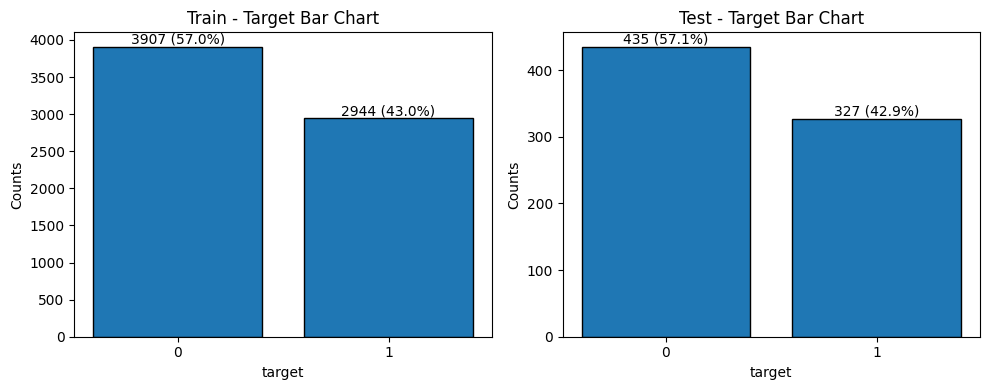

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, data, title in zip(axes, [train_df, test_df], ['Train', 'Test']):
    counts = data['target'].value_counts().sort_index()
    ax.bar(['0', '1'], counts.values, edgecolor='black')
    ax.set_title(f'{title} - Target Bar Chart')
    ax.set_xlabel('target')
    ax.set_ylabel('Counts')
    # πλήθος και ποσοστό πάνω από κάθε μπάρα
    for i, v in enumerate(counts.values):
        ax.text(i, v, f'{v} ({v / counts.sum() * 100:.1f}%)', ha='center', va='bottom')

plt.tight_layout()
plt.show()

## Ισορροπία Κλάσεων

Υπολογίζουμε το πλήθος και το ποσοστό κάθε κλάσης, καθώς και τον λόγο της μεγαλύτερης προς τη μικρότερη κλάση.

In [ ]:
for name, data in [('Train', train_df), ('Test', test_df)]:
    class_counts = data['target'].value_counts()
    class_percentages = (class_counts / len(data) * 100).round(2)
    print(name)
    print(pd.DataFrame({'Counts': class_counts, 'Percentage (%)': class_percentages}))
    print(f'Imbalance Ratio (majority / minority): {round(class_counts.max() / class_counts.min(), 2)}\n')

Train
        Counts  Percentage (%)
target                        
0         3907           57.03
1         2944           42.97
Imbalance Ratio (majority / minority): 1.33

Test
        Counts  Percentage (%)
target                        
0          435           57.09
1          327           42.91
Imbalance Ratio (majority / minority): 1.33



## Παρατηρήσεις

- Το dataset δεν είναι τελείως ισορροπημένο: περίπου 57% των tweets είναι στην κλάση 0 και 43% στην κλάση 1 (λόγος 1.33). Η ανισορροπία όμως είναι μικρή.
- Λόγω του stratify, τα ποσοστά είναι ίδια σε train και test.
- Ένα μοντέλο που προβλέπει πάντα 0 θα είχε ήδη 57% accuracy, οπότε θα κοιτάξουμε και precision, recall, F1.

# **2. Επεξεργασία Δεδομένων**

- a. Αφαιρούμε τις στήλες id, location.
- b. Συμπληρώνουμε τις ελλιπείς τιμές με "null".
- c. Ενώνουμε keyword και text στη στήλη inputs.

In [48]:
train_df.isna().sum()

,0
keyword,0
text,0
target,0
inputs,0


In [47]:
def preprocess(data):
    # Using errors='ignore' allows us to run this cell multiple times without KeyError
    data = data.drop(columns=['id', 'location'], errors='ignore')
    data = data.fillna('null')
    data['inputs'] = data['keyword'] + ' ' + data['text']
    return data

train_df = preprocess(train_df)
test_df = preprocess(test_df)

train_df.head()

,keyword,text,target,inputs
6669,threat,Meek Mill responds to DrakeÛªs OVO Fest set w...,1,threat Meek Mill responds to DrakeÛªs OVO Fes...
3940,flood,survived the plague\nfloated the flood\njust p...,0,flood survived the plague\nfloated the flood\n...
7217,weapons,#Kick Hendrixonfire @'=BLACKCATS= | BIG NOOB ...,0,weapons #Kick Hendrixonfire @'=BLACKCATS= | B...
2234,deluge,Vince McMahon once again a billionaire: I reme...,0,deluge Vince McMahon once again a billionaire:...
4233,hazardous,Is it possible to sneak into a hospital so I c...,0,hazardous Is it possible to sneak into a hospi...


# **3. Καθαρισμός Κειμένων (inputs)**

Χρησιμοποιούμε συναρτήσεις από το repository [Deffro/text-preprocessing-techniques](https://github.com/Deffro/text-preprocessing-techniques) (αρχείο techniques.py).

## Συναρτήσεις από το Repository

In [ ]:
def removeUnicode(text):
    ''' Removes unicode strings like "," and "x96" '''
    text = re.sub(r'(\\u[0-9A-Fa-f]+)', r'', text)
    text = re.sub(r'[^\x00-\x7f]', r'', text)
    return text

def replaceURL(text):
    ''' Replaces url address with "url" '''
    text = re.sub(r'((www\.[^\s]+)|(https?://[^\s]+))', 'url', text)
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text

def replaceAtUser(text):
    ''' Replaces "@user" with "atUser" '''
    text = re.sub(r'@[^\s]+', 'atUser', text)
    return text

def removeHashtagInFrontOfWord(text):
    ''' Removes hastag in front of a word '''
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text

def removeNumbers(text):
    ''' Removes integers '''
    text = ''.join([i for i in text if not i.isdigit()])
    return text

def removeEmoticons(text):
    ''' Removes emoticons from text '''
    text = re.sub(r':\)|;\)|:-\)|\(-:|:-D|=D|:P|xD|X-p|\^\^|:-*|\^\.\^|\^\-\^|\^\_\^|\,-\)|\)-:|:\'\(|:\(|:-\(|:\S|T\.T|\.\_\.|:<|:-\S|:-<|\*\-\*|:O|=O|=\-O|O\.o|XO|O\_O|:-\@|=/|:/|X\-\(|>\.<|>=\(|D:', '', text)
    return text

contraction_patterns = [(r'won\'t', 'will not'), (r'can\'t', 'cannot'), (r'i\'m', 'i am'), (r'ain\'t', 'is not'),
                        (r'(\w+)\'ll', r'\g<1> will'), (r'(\w+)n\'t', r'\g<1> not'), (r'(\w+)\'ve', r'\g<1> have'),
                        (r'(\w+)\'s', r'\g<1> is'), (r'(\w+)\'re', r'\g<1> are'), (r'(\w+)\'d', r'\g<1> would'),
                        (r'&', 'and'), (r'dammit', 'damn it'), (r'dont', 'do not'), (r'wont', 'will not')]

def replaceContraction(text):
    patterns = [(re.compile(regex), repl) for (regex, repl) in contraction_patterns]
    for (pattern, repl) in patterns:
        (text, count) = re.subn(pattern, repl, text)
    return text

## Lowercase, Punctuation, Stopwords

Για τις τεχνικές Lowercase, Remove Punctuation και Remove Stopwords του repository γράφουμε μικρές συναρτήσεις. Για τα stopwords χρησιμοποιούμε τη λίστα του scikit-learn, από την οποία βγάζουμε τη λέξη **fire**, γιατί είναι πολύ σημαντική για το πρόβλημά μας.

In [ ]:
print('fire in sklearn stopwords:', 'fire' in ENGLISH_STOP_WORDS)
stopwords = set(ENGLISH_STOP_WORDS) - {'fire'}


def toLowercase(text):
    return text.lower()

def removePunctuation(text):
    # τα σημεία στίξης γίνονται κενό για να μην ενωθούν λέξεις (π.χ. fire/smoke)
    return text.translate(str.maketrans(string.punctuation, ' ' * len(string.punctuation)))

def removeStopwords(text):
    return ' '.join(w for w in text.split() if w not in stopwords)

fire in sklearn stopwords: True


## Εφαρμογή στα Train - Test

In [ ]:
def clean_text(text):
    text = html.unescape(text)               # &amp; -> &
    text = text.replace('%20', ' ')          # στα keywords το κενό είναι %20 (π.χ. forest%20fire)
    text = removeUnicode(text)
    text = replaceURL(text)
    text = replaceAtUser(text)
    text = removeHashtagInFrontOfWord(text)
    text = removeEmoticons(text)             # πριν το lowercase, γιατί π.χ. το :D είναι κεφαλαίο
    text = toLowercase(text)
    text = replaceContraction(text)          # μετά το lowercase, τα patterns είναι με πεζά
    text = removeNumbers(text)
    text = removePunctuation(text)
    text = removeStopwords(text)
    return ' '.join(text.split())            # αφαιρεί τα πολλαπλά κενά


train_df['inputs'] = train_df['inputs'].apply(clean_text)
test_df['inputs'] = test_df['inputs'].apply(clean_text)

## Παραδείγματα Πριν - Μετά

In [ ]:
examples = df.loc[[31, 38, 62, 136, 4170]]
pd.DataFrame({'Before': (examples['keyword'].fillna('null') + ' ' + examples['text']).values,
              'After': [clean_text(t) for t in (examples['keyword'].fillna('null') + ' ' + examples['text'])]})

,Before,After
0,ablaze @bbcmtd Wholesale Markets ablaze http:/...,ablaze atuser wholesale markets ablaze url
1,ablaze Barbados #Bridgetown JAMAICA ÛÒ Two ca...,ablaze barbados bridgetown jamaica cars set ab...
2,ablaze Rene Ablaze &amp; Jacinta - Secret 2k13...,ablaze rene ablaze jacinta secret k fallen ski...
3,airplane%20accident Experts in France begin ex...,airplane accident experts france begin examini...
4,harm @wwexdreamer talk to please don't harm yo...,harm atuser talk harm self way shape form care...


## Περιγραφή Τεχνικών

*   **removeUnicode** : Αφαιρεί unicode κωδικούς και μη-ASCII χαρακτήρες (emoji, σύμβολα).
*   **replaceURL** : Αντικαθιστά τα links με τη λέξη url.
*   **replaceAtUser** : Αντικαθιστά τα @username με atUser.
*   **removeHashtagInFrontOfWord** : Αφαιρεί το # μπροστά από τις λέξεις.
*   **removeEmoticons** : Αφαιρεί emoticons όπως :) και :(.
*   **toLowercase** : Μετατρέπει όλα τα γράμματα σε πεζά.
*   **replaceContraction** : Αναπτύσσει τις συντμήσεις (can't → cannot).
*   **removeNumbers** : Αφαιρεί τους αριθμούς.
*   **removePunctuation** : Αφαιρεί τα σημεία στίξης.
*   **removeStopwords** : Αφαιρεί πολύ συχνές λέξεις (the, is, and, ...).

## Αιτιολόγηση

- Θέλουμε να καταλάβουμε το **θέμα** του tweet (καταστροφή ή όχι). Αυτό φαίνεται από λέξεις όπως fire, flood, earthquake, οπότε κρατάμε μόνο τις λέξεις και αφαιρούμε ό,τι άλλο.
- Links, usernames, αριθμοί και emoji είναι σχεδόν πάντα διαφορετικά σε κάθε tweet, οπότε απλώς μεγαλώνουν το λεξιλόγιο (άρα και τα χαρακτηριστικά του TF-IDF) χωρίς να βοηθάνε.
- Με lowercase και αφαίρεση του #, τα Fire, FIRE, #fire γίνονται η ίδια λέξη.
- Τα stopwords εμφανίζονται σε όλα τα tweets και των δύο κλάσεων, άρα δεν βοηθάνε να τις ξεχωρίσουμε.
- Δεν χρησιμοποιήσαμε spelling correction, lemmatizing, stemming κλπ., γιατί είναι αργά ή χρειάζονται επιπλέον λεξικά του NLTK και είναι πιο χρήσιμα στο sentiment analysis, για το οποίο φτιάχτηκε το repository.

# **4. Numpy Arrays - Inputs / Targets**

In [ ]:
x_train = train_df['inputs'].to_numpy()
y_train = train_df['target'].to_numpy()

x_test = test_df['inputs'].to_numpy()
y_test = test_df['target'].to_numpy()

x_train.shape, y_train.shape, x_test.shape, y_test.shape

((6851,), (6851,), (762,), (762,))

# **5. TF-IDF**

Κάθε tweet γίνεται ένα διάνυσμα με το tf-idf κάθε λέξης.

Κάνουμε fit_transform μόνο στο train (μαθαίνει το λεξιλόγιο και τα idf) και transform στο test, ώστε το test να μην επηρεάσει την εκπαίδευση.

In [ ]:
vectorizer = TfidfVectorizer()

x_train_tfidf = vectorizer.fit_transform(x_train)
x_test_tfidf = vectorizer.transform(x_test)

print(f'Vocabulary size: {len(vectorizer.vocabulary_)}')
print(f'Train shape: {x_train_tfidf.shape}')
print(f'Test shape: {x_test_tfidf.shape}')

Vocabulary size: 13107
Train shape: (6851, 13107)
Test shape: (762, 13107)


## Παράδειγμα TF-IDF για ένα Tweet

In [ ]:
words = vectorizer.get_feature_names_out()
row = x_train_tfidf[1].toarray()[0]

print(x_train[1])
pd.DataFrame({'word': words[row > 0], 'tf-idf': row[row > 0].round(3)}).sort_values('tf-idf', ascending=False)

flood survived plague floated flood just peeked heads mud immune deafening bells god survive


,word,tf-idf
3,flood,0.398
1,deafening,0.312
6,immune,0.312
9,peeked,0.312
8,mud,0.298
10,plague,0.289
2,floated,0.281
5,heads,0.275
0,bells,0.269
12,survived,0.213


## Παρατηρήσεις

- Ο πίνακας είναι πολύ αραιός (sparse): κάθε tweet έχει λίγες λέξεις, οπότε σχεδόν όλες οι τιμές είναι 0.
- Η λέξη flood, που εμφανίζεται δύο φορές στο tweet, έχει το μεγαλύτερο tf-idf.

# **6. Gaussian Naive Bayes**

Ο Naive Bayes υποθέτει ότι τα χαρακτηριστικά είναι ανεξάρτητα μεταξύ τους και διαλέγει την κλάση με τη μεγαλύτερη πιθανότητα.

Ο Gaussian NB είναι η επέκταση για αριθμητικές τιμές (όπως το tf-idf) και υποθέτει ότι κάθε χαρακτηριστικό ακολουθεί κανονική κατανομή σε κάθε κλάση. Ο GaussianNB δεν δέχεται sparse πίνακα, οπότε τον μετατρέπουμε με toarray().

In [ ]:
x_train_dense = x_train_tfidf.toarray()
x_test_dense = x_test_tfidf.toarray()

model = GaussianNB()
model.fit(x_train_dense, y_train)

# p(y) για κάθε κλάση, μ και σ² για κάθε λέξη ανά κλάση
print(f'Class priors p(y): {model.class_prior_.round(4)}')
print(f'Means shape: {model.theta_.shape}')
print(f'Variances shape: {model.var_.shape}')

Class priors p(y): [0.5703 0.4297]
Means shape: (2, 13107)
Variances shape: (2, 13107)


## Evaluate Model on Train - Test

In [ ]:
y_pred_train = model.predict(x_train_dense)
y_pred = model.predict(x_test_dense)

print(f'Train Accuracy: {accuracy_score(y_train, y_pred_train) * 100:.2f}%')
print(f'Test Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n')
print(classification_report(y_test, y_pred, digits=4))

Train Accuracy: 87.71%
Test Accuracy: 61.29%

              precision    recall  f1-score   support

           0     0.7593    0.4713    0.5816       435
           1     0.5325    0.8012    0.6398       327

    accuracy                         0.6129       762
   macro avg     0.6459    0.6362    0.6107       762
weighted avg     0.6620    0.6129    0.6066       762



## Confusion Matrix

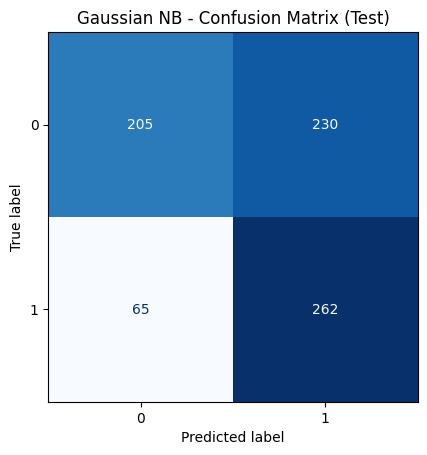

In [ ]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['0', '1']).plot(cmap='Blues', colorbar=False)
plt.title('Gaussian NB - Confusion Matrix (Test)')
plt.grid(False)
plt.show()

## Παρατηρήσεις

- Τα priors p(y) είναι ίδια με τα ποσοστά των κλάσεων στο train (57% - 43%).
- Train accuracy 87.71% αλλά Test accuracy μόνο 61.29%, άρα έχουμε **overfitting**. Το test είναι λίγο πάνω από το 57% που θα έπαιρνε ένα μοντέλο που λέει πάντα 0.
- Για την κλάση 1 το recall είναι υψηλό (80%) αλλά το precision χαμηλό (53%). Από τα 435 tweets που δεν αφορούν καταστροφή, τα 230 προβλέφθηκαν λάθος ως καταστροφή, δηλαδή το σύστημα θα έστελνε πολλά λάθος μηνύματα στο 112.
- Η απόδοση είναι χαμηλή γιατί δεν ισχύουν οι υποθέσεις του GNB:
  - Οι τιμές tf-idf **δεν ακολουθούν κανονική κατανομή**: για κάθε λέξη είναι σχεδόν παντού 0. Πολλές λέξεις εμφανίζονται σε ελάχιστα tweets μιας κλάσης, άρα η διασπορά τους είναι σχεδόν 0 και μια σπάνια λέξη αρκεί για να αλλάξει την πρόβλεψη.
  - Οι λέξεις **δεν είναι ανεξάρτητες** (π.χ. forest και fire εμφανίζονται μαζί).